# 05 - Feature Engineering

**Design rule:** a feature may only use information that is available at the forecast origin.

The project uses **direct multi-horizon features**: for a forecast made on day `T`, every feature is anchored at `T`, and the target can be any day in `T+1 .. T+48`. Training rows are built with a 48-day information lag, so the model never sees data that would not have been available 48 days before the target. This avoids the recursive error accumulation documented in the data-understanding notebook (one-step RMSPE 0.195 vs recursive 0.38 for the same linear model).

**Feature groups**

| Group | Examples | Why it matters |
|---|---|---|
| Calendar | weekday, month, week of year, day of year, sin/cos | weekly and annual seasonality |
| Store | store type, assortment, competition distance/log, competition age | structural differences between locations |
| Promotion | `Promo`, `Promo2Active`, promo share of last 28 days | short-term demand shocks |
| History | lags 1/7/14/28/365, rolling means 7/28/90/365, rolling std | store level and momentum, anchored at the origin |
| Customer history | 28-day average customers, sales per customer | traffic and basket information, frozen at the origin |

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Project root:", PROJECT_ROOT)

Project root: rossmann-sales-forecasting


## 1. Build features for a small sample

`build_training_matrix` returns `X`, `log1p(Sales)` and a metadata frame. The sample below uses three stores so the table is readable; the pipeline scales to all 1,115.

In [2]:
from src.data_preparation import load_processed
from src.features import build_training_matrix, FEATURE_COLUMNS

data = load_processed()
train, store = data["train"], data["store"]
sample = train[train.Store.isin([1, 2, 3]) & (train.Date <= "2015-06-14")]

X, y, meta = build_training_matrix(sample, store, history_offset=48)
print("X shape:", X.shape)
print("Number of features:", len(FEATURE_COLUMNS))
display(meta.head(3))
display(X[["DayOfWeek", "Promo", "sales_lag_1", "sales_roll_mean_28", "sales_roll_mean_365",
           "customers_roll_mean_28", "CompetitionOpenMonths"]].head(8).round(3))

X shape: (2221, 46)
Number of features: 46


,Store,Date,Sales,Promo,SchoolHoliday,IsStateHoliday,StoreType
0,1,2013-01-02,5530,0,1,0,c
1,1,2013-01-03,4327,0,1,0,c
2,1,2013-01-04,4486,0,1,0,c


,DayOfWeek,Promo,sales_lag_1,sales_roll_mean_28,sales_roll_mean_365,customers_roll_mean_28,CompetitionOpenMonths
1,3.0,0.0,NaN,NaN,NaN,NaN,52.036999
2,4.0,0.0,NaN,NaN,NaN,NaN,52.070000
3,5.0,0.0,NaN,NaN,NaN,NaN,52.102001
4,6.0,0.0,NaN,NaN,NaN,NaN,52.134998
6,1.0,1.0,NaN,NaN,NaN,NaN,52.201000
7,2.0,1.0,NaN,NaN,NaN,NaN,52.234001
8,3.0,1.0,NaN,NaN,NaN,NaN,52.266998
9,4.0,1.0,NaN,NaN,NaN,NaN,52.299999


**Reading the table.** `sales_lag_1` is the last observed sales value at the forecast origin (48 days before the target in training). `sales_roll_mean_28` is the average log sales over the 28 days ending at the origin. `Promo` is the promotion status of the **target** day, because promotions are scheduled in advance. This mix of target-day calendar information and origin-day history is the core of a direct multi-horizon model.

## 2. Prove the absence of leakage

The strongest test is a **future-perturbation test**: change sales after a cutoff date, rebuild all features, and verify that every feature row up to the cutoff is unchanged. If any future value leaked into a lag or rolling window, this test would fail.

In [3]:
from src.features import build_training_matrix

cutoff = pd.Timestamp("2015-03-01")
base = train[train.Store.isin([1, 2, 3]) & (train.Date <= "2015-06-14")]
perturbed = base.copy()
future_rows = perturbed.Date > cutoff
perturbed.loc[future_rows, "Sales"] = perturbed.loc[future_rows, "Sales"] + 1000

X_base, y_base, meta_base = build_training_matrix(base, store, history_offset=48)
X_pert, y_pert, meta_pert = build_training_matrix(perturbed, store, history_offset=48)

before = (meta_base.Date <= cutoff).to_numpy()
assert before.sum() == (meta_pert.Date <= cutoff).sum()
difference = (X_base.loc[before].fillna(-999) - X_pert.loc[before].fillna(-999)).abs().max().max()
print(f"Rows compared: {before.sum():,}")
print(f"Maximum absolute feature difference before the cutoff: {difference:.6f}")
assert difference == 0, "Leakage detected: future sales changed a past feature"
print("PASS - perturbing future sales did not change any feature before the cutoff.")

Rows compared: 1,968
Maximum absolute feature difference before the cutoff: 0.000000
PASS - perturbing future sales did not change any feature before the cutoff.


The same guarantee is enforced by `tests/test_features.py`, which also checks that the first lag equals the previous calendar day's sales and that rolling windows never include the target day.

## 3. Feature groups in the final matrix

In [4]:
groups = {
    "calendar": ["DayOfWeek", "Month", "WeekOfYear", "Quarter", "Day", "DayOfYear", "IsWeekend", "IsMonthStart",
                 "IsMonthEnd", "SinDayOfYear", "CosDayOfYear", "SinDayOfWeek", "CosDayOfWeek"],
    "store": ["StoreType_b", "StoreType_c", "StoreType_d", "Assortment_b", "Assortment_c",
              "CompetitionDistanceLog", "CompetitionOpenMonths", "HasCompetitionStart", "Promo2"],
    "promotion": ["Promo", "PromoYesterday", "PromoTomorrow", "Promo2Active", "Promo2MonthsSinceStart", "promo_share_28"],
    "holiday": ["SchoolHoliday", "StateHoliday_a", "StateHoliday_b", "StateHoliday_c"],
    "history": ["sales_lag_1", "sales_lag_7", "sales_lag_14", "sales_lag_28", "sales_lag_365",
                "sales_roll_mean_7", "sales_roll_mean_28", "sales_roll_mean_90", "sales_roll_mean_365",
                "sales_roll_std_28", "sales_momentum_1_28", "sales_short_vs_long"],
    "customer history": ["customers_roll_mean_28", "sales_per_customer_roll_28"],
}
for group, columns in groups.items():
    missing = [c for c in columns if c not in FEATURE_COLUMNS]
    print(f"{group:16s} {len(columns):2d} features" + (f"  MISSING: {missing}" if missing else ""))

print("Total:", len(FEATURE_COLUMNS))

calendar         13 features
store             9 features
promotion         6 features
holiday           4 features
history          12 features
customer history  2 features
Total: 46


## 4. Feature importance in the final model

The chart uses the gain-based importance of the fitted gradient-boosted model. Importance is descriptive, not causal: a high-importance promotion feature means the model splits on it often, not that promotions cause the observed sales difference.

,gain_importance
Promo,0.309478
sales_roll_mean_365,0.098287
sales_roll_mean_90,0.082120
PromoTomorrow,0.072788
sales_lag_1,0.032381
customers_roll_mean_28,0.030165
sales_roll_std_28,0.026667
DayOfWeek,0.023421
IsMonthEnd,0.020196
SinDayOfWeek,0.018742


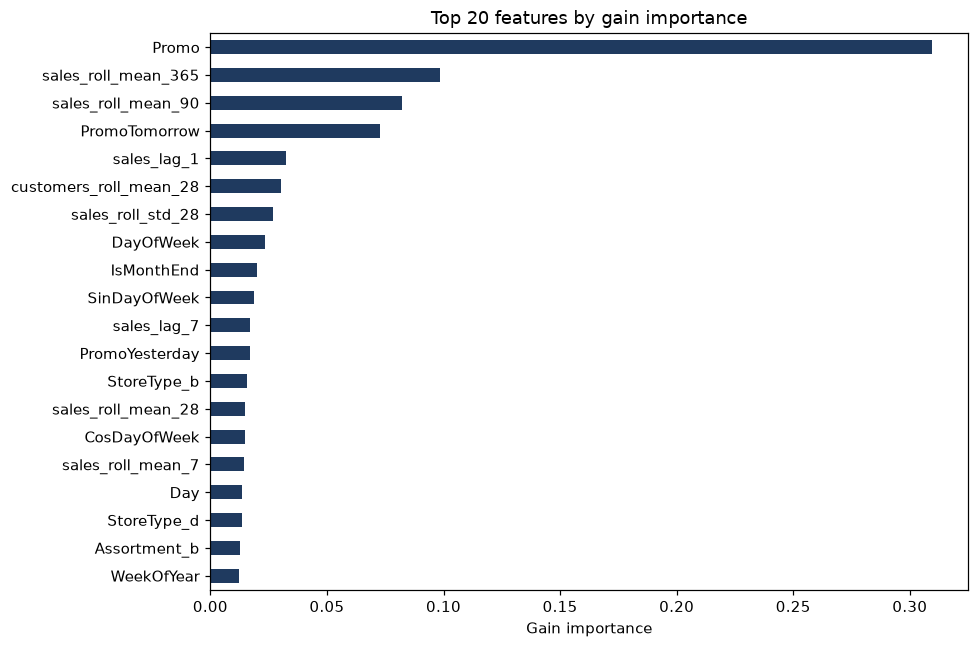

In [5]:
import joblib

model_files = sorted((PROJECT_ROOT / "outputs" / "models").glob("final_*.joblib"))
if model_files:
    artifact = joblib.load(model_files[-1])
    model = artifact["model"]
    features = artifact["features"]
    importance = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
    display(importance.head(20).to_frame("gain_importance"))

    fig, ax = plt.subplots(figsize=(9, 6))
    importance.head(20).iloc[::-1].plot(kind="barh", ax=ax, color="#1f3a5f")
    ax.set_title("Top 20 features by gain importance")
    ax.set_xlabel("Gain importance")
    plt.tight_layout()
    plt.show()
else:
    print("Run `python -m src.predict` first to create the final model artefact.")

## 5. Design choices and trade-offs

**Why log1p(Sales)?** Sales are right-skewed; the log transform stabilises variance and turns the regression into an approximate percentage-error model, which aligns with RMSPE.

**Why direct instead of recursive?** Recursive forecasts feed predictions back into lag features for up to 48 steps. In a controlled pilot, the linear model's holdout RMSPE rose from 0.195 (one-step) to 0.38 (recursive). Direct features anchored at the origin avoid that failure mode.

**Why freeze customer features?** Customers are unknown for future days. The 28-day average at the origin is legitimate; a contemporaneous customer count is not.

**What is deliberately excluded?** Raw `Store` ID (the model would memorise stores instead of learning transferable patterns), future `Sales`/`Customers`, and any statistic computed on the validation or test window.

**Known limitation.** Direct features cannot react to a demand shock that occurs inside the 48-day horizon. A production system would re-run the model weekly with a shorter horizon; the competition setup does not allow that.